# Solar Micro-Grid Dispatch Planner

This project models daily solar and battery energy dispatch for a rural health centre in Kasese. The reusable solver classes are in [`src/solar.py`](src/solar.py); this notebook generates and reads the sample CSV, performs analysis, reports costs, and visualizes results.

Population is not involved here: energy values are in kWh and costs are illustrative UGX rates.

## Model and assumptions

The daily dispatch variables are solar energy `x` and battery energy `y`:

$$3x + 2y = D_1, \qquad 4x + y = D_2.$$

The equations encode the assignment's simplified demand constraints. A mathematically valid solution can still be physically impossible if either source dispatch is negative. The least-squares nonnegative fallback will be used for such days and its residual reported because it may no longer satisfy both equalities exactly.

In [31]:
import csv
from pathlib import Path
import statistics
import timeit

import matplotlib.pyplot as plt
import numpy as np

from src.solar import HybridMicroGrid, MicroGrid

DATA_PATH = Path("data/solar_demands_30_days.csv")
RANDOM_SEED = 20261010
SOLAR_RATE_UGX_PER_KWH = 150
BATTERY_RATE_UGX_PER_KWH = 450
DAYS_IN_MONTH = 30

## 1. Check the system is well-posed

The determinant tells whether this square system has a unique solution: a zero determinant means the equations are linearly dependent and no unique dispatch can be recovered. The condition number measures sensitivity: larger values mean small relative changes in demand can create larger relative changes in the computed dispatch. It depends on the matrix and norm convention, and is not itself a forecast-error estimate.

For the assigned coefficient matrix the determinant is `-5`, so the system is nonsingular. The condition number below gives its numerical sensitivity scale.

In [32]:
grid = MicroGrid(
    solar_cost_per_kwh=SOLAR_RATE_UGX_PER_KWH,
    battery_cost_per_kwh=BATTERY_RATE_UGX_PER_KWH,
)
print("Coefficient matrix:")
print(grid.coefficient_matrix)
print(f"Determinant: {grid.determinant:.2f}")
print(f"2-norm condition number: {grid.condition_number:.4f}")
grid.solve_day(50, 50)

Coefficient matrix:
[[3. 2.]
 [4. 1.]]
Determinant: -5.00
2-norm condition number: 5.8284


array([10., 10.])

## 2. Generate a reproducible 30-day demand CSV

The sample models higher daytime demand on weekdays and lower demand on weekends, with independent Gaussian measurement variation. A fixed random seed makes regeneration repeatable. The CSV is saved at `data/solar_demands_30_days.csv` so it can also be loaded independently of this notebook.

In [33]:
def generate_demand_csv(path: Path = DATA_PATH, seed: int = RANDOM_SEED) -> None:
    rng = np.random.default_rng(seed)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow(["day", "d1_kwh", "d2_kwh"])
        for day in range(30):
            weekday = day % 7
            business_day = weekday < 5
            elevated_clinic_activity = weekday in (1, 2, 3)
            d1 = (48 if business_day else 40) + (6 if elevated_clinic_activity else 0)
            d2 = (42 if business_day else 36) + (4 if elevated_clinic_activity else 0)
            d1 += rng.normal(0, 2.0)
            d2 += rng.normal(0, 1.5)
            writer.writerow([day + 1, f"{d1:.2f}", f"{d2:.2f}"])


generate_demand_csv()
print(f"Generated {DATA_PATH} with a fixed seed ({RANDOM_SEED}).")

Generated data\solar_demands_30_days.csv with a fixed seed (20261010).


## 3. Load the CSV and verify its contents

The CSV reader checks the required column names, row count, finite/nonnegative demand values, and unique day identifiers before dispatch. This catches malformed input early rather than silently producing partial results.

In [34]:
def load_demands_csv(path: Path = DATA_PATH) -> tuple[list[int], np.ndarray]:
    with path.open("r", newline="", encoding="utf-8") as csv_file:
        reader = csv.DictReader(csv_file)
        required = {"day", "d1_kwh", "d2_kwh"}
        if reader.fieldnames is None or not required.issubset(reader.fieldnames):
            raise ValueError(f"CSV must include columns: {sorted(required)}")
        rows = list(reader)
    if len(rows) != DAYS_IN_MONTH:
        raise ValueError(f"Expected {DAYS_IN_MONTH} demand rows, found {len(rows)}.")
    try:
        days = [int(row["day"]) for row in rows]
        demands = np.array(
            [[float(row["d1_kwh"]), float(row["d2_kwh"])] for row in rows],
            dtype=float,
        )
    except (TypeError, ValueError) as error:
        raise ValueError("CSV contains an invalid day or demand value.") from error
    if len(set(days)) != DAYS_IN_MONTH:
        raise ValueError("CSV day identifiers must be unique.")
    if not np.all(np.isfinite(demands)) or np.any(demands < 0):
        raise ValueError("CSV demands must be finite and nonnegative.")
    return days, demands


days, demands = load_demands_csv()
print(f"Loaded {len(days)} days from {DATA_PATH}.")
print("First five demand rows (day, D1, D2):")
print(np.column_stack((days, demands))[:5])

Loaded 30 days from data\solar_demands_30_days.csv.
First five demand rows (day, D1, D2):
[[ 1.   49.98 43.12]
 [ 2.   54.59 45.37]
 [ 3.   52.01 44.11]
 [ 4.   60.38 46.11]
 [ 5.   46.72 39.13]]


## 4. Interactive input mode

Run the next cell when an operator wants to enter one day manually. The prompt repeats for empty, non-numeric, negative, or non-finite values. It is defined but not called automatically so opening or running the whole notebook does not unexpectedly block for keyboard input.

In [35]:
def prompt_nonnegative_demand(prompt: str) -> float:
    while True:
        raw_value = input(prompt).strip()
        if not raw_value:
            print("Please enter a value; empty input is not allowed.")
            continue
        try:
            value = float(raw_value)
        except ValueError:
            print("Please enter a numeric value.")
            continue
        if not np.isfinite(value):
            print("Please enter a finite value.")
            continue
        if value < 0:
            print("Demand cannot be negative.")
            continue
        return value


def run_interactive_day(micro_grid: MicroGrid = grid) -> np.ndarray:
    d1 = prompt_nonnegative_demand("Daytime demand D1 (kWh): ")
    d2 = prompt_nonnegative_demand("Critical-equipment demand D2 (kWh): ")
    dispatch = micro_grid.solve_day(d1, d2)
    print(f"Solar: {dispatch[0]:.2f} kWh; battery: {dispatch[1]:.2f} kWh")
    return dispatch


# Uncomment to enter one day's demand interactively:
# interactive_dispatch = run_interactive_day()

## 5. Solve the 30 days in a Python loop

The loop calls the single-day `scipy.linalg.solve` method for each demand pair. Results are reported in `[solar, battery]` column order.

In [36]:
loop_dispatch = grid.solve_days_loop(demands)
print("First five loop-solved dispatches (solar kWh, battery kWh):")
print(np.round(loop_dispatch[:5], 2))

First five loop-solved dispatches (solar kWh, battery kWh):
[[ 7.25 14.11]
 [ 7.23 16.45]
 [ 7.24 15.14]
 [ 6.37 20.64]
 [ 6.31 13.9 ]]


## 6. Solve all days with one vectorized call

For multiple right-hand sides, SciPy accepts a matrix of shape `(2, 30)`: one demand vector per column. The class transposes the input to this form, solves once, then returns the dispatches as `(30, 2)` rows for easier reporting.

In [37]:
vectorized_dispatch = grid.solve_days_vectorized(demands)
print("First five vectorized dispatches:")
print(np.round(vectorized_dispatch[:5], 2))
np.testing.assert_allclose(loop_dispatch, vectorized_dispatch)
print("Loop and vectorized results agree within floating-point tolerance.")

First five vectorized dispatches:
[[ 7.25 14.11]
 [ 7.23 16.45]
 [ 7.24 15.14]
 [ 6.37 20.64]
 [ 6.31 13.9 ]]
Loop and vectorized results agree within floating-point tolerance.


## 7. Time both approaches

The timings below repeat each complete 30-day operation. A two-by-two solve is tiny, so Python-loop overhead and timer noise can be comparable to the calculation itself. The vectorized result should be judged by repeated measurements, not a single timing; either way, both methods should produce matching values.

In [23]:
number = 2_000
loop_seconds = min(timeit.repeat(lambda: grid.solve_days_loop(demands), number=number, repeat=5)) / number
vectorized_seconds = min(timeit.repeat(lambda: grid.solve_days_vectorized(demands), number=number, repeat=5)) / number
print(f"Best loop time per 30-day batch:       {loop_seconds * 1e6:.2f} µs")
print(f"Best vectorized time per 30-day batch: {vectorized_seconds * 1e6:.2f} µs")
if vectorized_seconds > 0:
    print(f"Loop / vectorized ratio: {loop_seconds / vectorized_seconds:.2f}x")
print("For only 30 days, the practical difference is small; batching scales better for many days.")

Best loop time per 30-day batch:       5176.48 µs
Best vectorized time per 30-day batch: 259.61 µs
Loop / vectorized ratio: 19.94x
For only 30 days, the practical difference is small; batching scales better for many days.


## 8. Flag infeasible dispatches and handle them with NNLS

A negative solar or battery value is not physically dispatchable. We preserve the raw linear solution for diagnosing the assigned equations, flag each infeasible day, and replace it with the closest nonnegative least-squares (`scipy.optimize.nnls`) solution. The residual norm reports the mismatch from the original demand equations.

The generated monthly sample may contain no infeasible days. A deliberately challenging diagnostic demand is also evaluated so the fallback behavior is visible even when all sample rows are feasible.

In [24]:
raw_dispatch = vectorized_dispatch.copy()
infeasible_mask = np.any(raw_dispatch < 0, axis=1)
dispatch = raw_dispatch.copy()
nnls_residuals = np.zeros(len(days), dtype=float)

for index in np.flatnonzero(infeasible_mask):
    dispatch[index], nnls_residuals[index] = grid.solve_nonnegative_day(*demands[index])
    print(
        f"FLAG day {days[index]}: raw={raw_dispatch[index].round(2).tolist()}, "
        f"NNLS={dispatch[index].round(2).tolist()}, "
        f"demand residual={nnls_residuals[index]:.3f}"
    )

if not np.any(infeasible_mask):
    print("No infeasible days in the generated 30-day dataset.")

diagnostic_demand = (40.0, 10.0)
diagnostic_raw = grid.solve_day(*diagnostic_demand)
diagnostic_nnls, diagnostic_residual = grid.solve_nonnegative_day(*diagnostic_demand)
print(f"\nDiagnostic demand {diagnostic_demand}: raw dispatch={diagnostic_raw.round(2)}")
print(
    f"NNLS dispatch={diagnostic_nnls.round(2)}, "
    f"residual={diagnostic_residual:.3f} (not an exact solution to both equations)"
)

No infeasible days in the generated 30-day dataset.

Diagnostic demand (40.0, 10.0): raw dispatch=[-4. 26.]
NNLS dispatch=[ 0. 18.], residual=8.944 (not an exact solution to both equations)


## 9. Mean, variance and standard deviation

These are descriptive statistics across the 30 dispatch days. `statistics.variance` and `statistics.stdev` are sample estimates (they use `n − 1`). We compare standard deviations to identify which source's daily usage fluctuates more in absolute kWh; variance uses squared kWh.

In [25]:
solar_usage = dispatch[:, 0]
battery_usage = dispatch[:, 1]
usage_statistics = {}

for label, values in (("Solar", solar_usage), ("Battery", battery_usage)):
    usage_statistics[label] = {
        "mean": statistics.mean(values),
        "variance": statistics.variance(values),
        "stdev": statistics.stdev(values),
    }
    summary = usage_statistics[label]
    print(
        f"{label:8} mean={summary['mean']:.2f} kWh | "
        f"sample variance={summary['variance']:.2f} kWh² | "
        f"sample stdev={summary['stdev']:.2f} kWh"
    )

more_volatile = max(usage_statistics, key=lambda name: usage_statistics[name]["stdev"])
print(f"\nMore volatile by absolute daily standard deviation: {more_volatile}")

Solar    mean=7.06 kWh | sample variance=0.92 kWh² | sample stdev=0.96 kWh
Battery  mean=14.02 kWh | sample variance=7.36 kWh² | sample stdev=2.71 kWh

More volatile by absolute daily standard deviation: Battery


## 10. Daily and monthly energy cost

The illustrative energy rates are UGX 150 per solar kWh and UGX 450 per battery kWh. Daily energy cost is the sum of each source's use times its rate. The monthly total is the sum across these 30 days; it is not extrapolated from a shorter sample.

In [26]:
daily_cost = np.array(
    [grid.calculate_cost(solar, battery) for solar, battery in dispatch],
    dtype=float,
)
monthly_cost = float(np.sum(daily_cost))
print(f"Average daily cost: UGX {statistics.mean(daily_cost):,.2f}")
print(f"30-day energy cost: UGX {monthly_cost:,.2f}")
print("\nDaily cost by day:")
for day, cost in zip(days, daily_cost):
    print(f"  Day {day:2}: UGX {cost:,.2f}")

Average daily cost: UGX 7,365.81
30-day energy cost: UGX 220,974.30

Daily cost by day:
  Day  1: UGX 7,438.20
  Day  2: UGX 8,487.00
  Day  3: UGX 7,900.20
  Day  4: UGX 10,242.30
  Day  5: UGX 7,200.30
  Day  6: UGX 6,711.00
  Day  7: UGX 6,059.70
  Day  8: UGX 7,325.70
  Day  9: UGX 7,705.80
  Day 10: UGX 5,687.10
  Day 11: UGX 8,106.60
  Day 12: UGX 6,622.20
  Day 13: UGX 4,529.40
  Day 14: UGX 6,434.40
  Day 15: UGX 7,887.00
  Day 16: UGX 8,496.30
  Day 17: UGX 9,073.80
  Day 18: UGX 7,409.40
  Day 19: UGX 7,971.90
  Day 20: UGX 6,364.50
  Day 21: UGX 6,366.60
  Day 22: UGX 5,759.40
  Day 23: UGX 8,024.70
  Day 24: UGX 8,874.60
  Day 25: UGX 8,688.30
  Day 26: UGX 7,015.80
  Day 27: UGX 6,402.00
  Day 28: UGX 6,405.60
  Day 29: UGX 6,946.50
  Day 30: UGX 8,838.00


## 11. Plot usage and daily cost

The stacked bars show solar and battery dispatch in kWh. The secondary y-axis overlays the daily UGX cost as a line, making the higher battery tariff visible in the cost pattern.

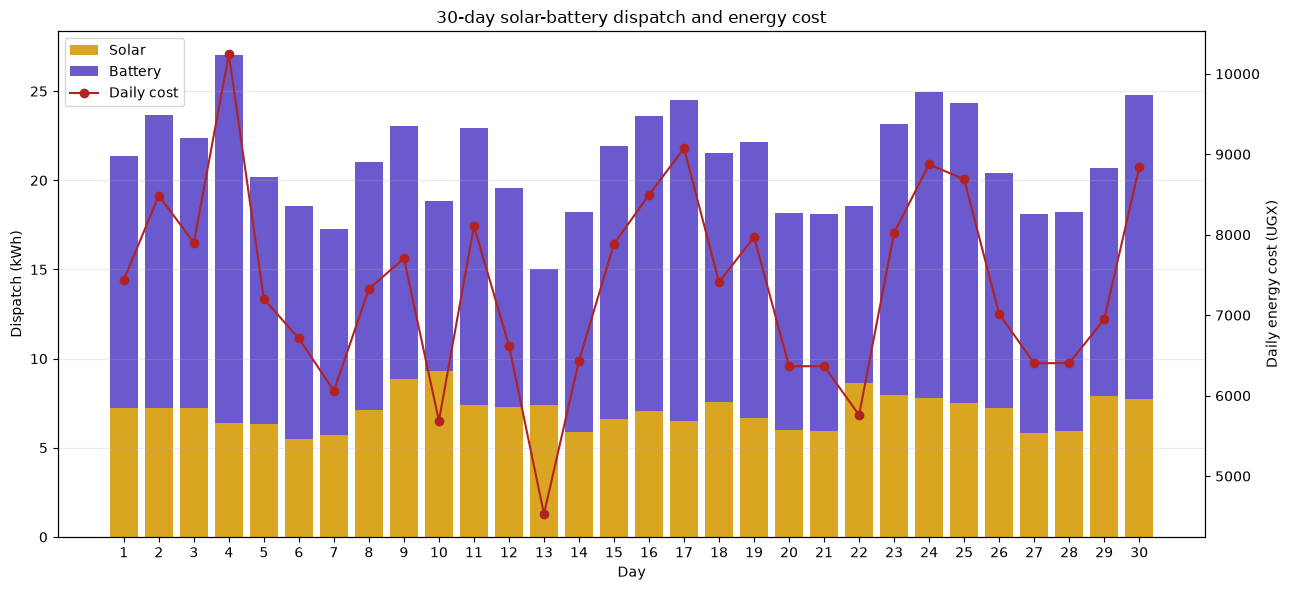

In [27]:
figure, usage_axis = plt.subplots(figsize=(13, 6))
usage_axis.bar(days, solar_usage, label="Solar", color="goldenrod")
usage_axis.bar(
    days,
    battery_usage,
    bottom=solar_usage,
    label="Battery",
    color="slateblue",
)
usage_axis.set_xlabel("Day")
usage_axis.set_ylabel("Dispatch (kWh)")
usage_axis.set_xticks(days)
usage_axis.grid(axis="y", alpha=0.25)
cost_axis = usage_axis.twinx()
cost_axis.plot(days, daily_cost, color="firebrick", marker="o", label="Daily cost")
cost_axis.set_ylabel("Daily energy cost (UGX)")
handles_a, labels_a = usage_axis.get_legend_handles_labels()
handles_b, labels_b = cost_axis.get_legend_handles_labels()
usage_axis.legend(handles_a + handles_b, labels_a + labels_b, loc="upper left")
usage_axis.set_title("30-day solar-battery dispatch and energy cost")
figure.tight_layout()
plt.show()

## 12. Monte Carlo sensitivity to ±5% demand changes

For each of 1,000 trials, both demands are independently perturbed by a uniformly sampled factor from 95% to 105% of their baseline monthly means. We solve each perturbed system and report absolute movement in solar and battery dispatch. The relative 2-norm change in dispatch is also compared with the matrix condition-number bound: for small relative perturbations, output relative change is bounded approximately by `cond(A) × input relative change`, though a bound is not a prediction of typical movement.

In [28]:
rng = np.random.default_rng(RANDOM_SEED + 1)
baseline_demand = np.mean(demands, axis=0)
perturbation_factors = rng.uniform(0.95, 1.05, size=(1_000, 2))
perturbed_demands = baseline_demand * perturbation_factors
sensitivity_dispatch = grid.solve_days_vectorized(perturbed_demands)
baseline_dispatch = grid.solve_day(*baseline_demand)
absolute_movement = np.abs(sensitivity_dispatch - baseline_dispatch)
demand_relative_change = np.linalg.norm(
    perturbed_demands - baseline_demand, axis=1
) / np.linalg.norm(baseline_demand)
dispatch_relative_change = np.linalg.norm(
    sensitivity_dispatch - baseline_dispatch, axis=1
) / np.linalg.norm(baseline_dispatch)

print(f"Baseline mean demand [D1, D2]: {baseline_demand.round(2)} kWh")
print(f"Baseline dispatch [solar, battery]: {baseline_dispatch.round(2)} kWh")
for index, label in enumerate(("Solar", "Battery")):
    print(
        f"{label} absolute movement: median={np.median(absolute_movement[:, index]):.3f} kWh, "
        f"95th percentile={np.percentile(absolute_movement[:, index], 95):.3f} kWh, "
        f"maximum={np.max(absolute_movement[:, index]):.3f} kWh"
    )
print(
    f"Observed relative dispatch movement, 95th percentile: "
    f"{np.percentile(dispatch_relative_change, 95):.2%}"
)
print(
    f"Condition-number upper-bound scale from the maximum sampled input change: "
    f"{grid.condition_number * np.max(demand_relative_change):.2%}"
)

Baseline mean demand [D1, D2]: [49.2  42.25] kWh
Baseline dispatch [solar, battery]: [ 7.06 14.02] kWh
Solar absolute movement: median=0.405 kWh, 95th percentile=1.041 kWh, maximum=1.291 kWh
Battery absolute movement: median=0.945 kWh, 95th percentile=2.576 kWh, maximum=3.164 kWh
Observed relative dispatch movement, 95th percentile: 17.77%
Condition-number upper-bound scale from the maximum sampled input change: 28.46%


## Extension: add a diesel generator

For the third equation, choose total delivered energy: `x + y + z = D3`. Here `D3` is the total energy target in kWh and `z` is diesel energy. The default hybrid matrix is nonsingular, so it has one algebraic solution for solar, battery, and diesel. The following example checks that the solution satisfies all three equations.

In [29]:
hybrid = HybridMicroGrid()
hybrid_demand = np.array([50.0, 50.0, 30.0])
hybrid_dispatch = hybrid.solve_day(*hybrid_demand)
print("Hybrid coefficient matrix:")
print(hybrid.coefficient_matrix)
print(f"Determinant: {hybrid.determinant:.2f}")
print(f"Condition number: {hybrid.condition_number:.4f}")
print(f"[solar, battery, diesel] dispatch: {hybrid_dispatch.round(2)} kWh")
print(f"Reconstructed demands: {(hybrid.coefficient_matrix @ hybrid_dispatch).round(2)} kWh")

Hybrid coefficient matrix:
[[3. 2. 0.]
 [4. 1. 0.]
 [1. 1. 1.]]
Determinant: -5.00
Condition number: 7.7158
[solar, battery, diesel] dispatch: [10. 10. 10.] kWh
Reconstructed demands: [50. 50. 30.] kWh


### What if the third equation is dependent?

If the third coefficient row is the sum of the first two, `(7, 3, 0) = (3, 2, 0) + (4, 1, 0)`, the matrix has determinant zero. If its demand is also `D1 + D2`, the new equation adds no information; there are infinitely many compatible triples because diesel does not appear independently. If the demand is inconsistent with `D1 + D2`, there is no exact solution. Either way, a direct square-system solve cannot produce a unique reliable dispatch; the class checks determinant and condition number and rejects the singular system.

In [30]:
dependent_hybrid = HybridMicroGrid(
    coefficient_matrix=((3, 2, 0), (4, 1, 0), (7, 3, 0))
)
print(f"Dependent matrix determinant: {dependent_hybrid.determinant:.2f}")
print(f"Dependent matrix condition number: {dependent_hybrid.condition_number}")
try:
    dependent_hybrid.solve_day(50, 50, 100)
except np.linalg.LinAlgError as error:
    print(f"Expected result: {error}")

Dependent matrix determinant: 0.00
Dependent matrix condition number: inf
Expected result: The demand system is singular or ill-conditioned; a reliable unique dispatch cannot be computed.


## Conclusions

- The two-equation dispatch model is uniquely solvable for the supplied coefficient matrix because its determinant is nonzero. Its condition number quantifies sensitivity to relative demand changes.
- The loop and vectorized solvers return equivalent dispatches. For a 30-day dataset, the speed difference may be modest; vectorized solving is more convenient and scalable for many right-hand sides.
- Negative algebraic dispatches are flagged as infeasible. NNLS returns the closest nonnegative dispatch, with a residual that should be treated as unmet/mismatched model demand rather than hidden by clipping.
- Which source is more volatile, the 30-day cost, and demand sensitivity are reported from the generated seeded sample above. These results describe the sample and assumptions, not actual measured Kasese operations.
- The hybrid extension only has a unique solution when its third equation contributes independent information. A linearly dependent equation leaves the system singular.

The rates, demand pattern, and equations are illustrative. Operational planning would require measured load profiles, battery efficiency and state-of-charge limits, solar availability, generator constraints, and validated tariffs.